# Agente de voz com IA na API da Fluke

A Fluke faz a ligação a partir de um número brasileiro, dentro da rede brasileira. O seu agente de IA entra na chamada por SIP. Este notebook usa o OpenAI Realtime; qualquer IA que aceite SIP funciona do mesmo jeito (passo 7).

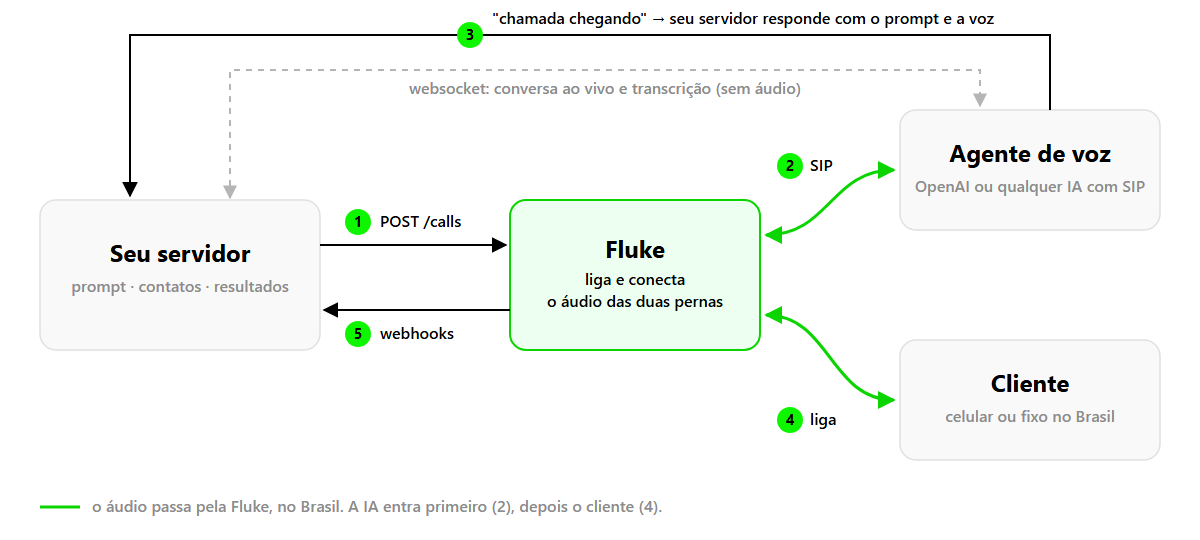

Você precisa de: uma chave da API da Fluke e um número fixo da Fluke, mais uma chave e um projeto da OpenAI. Tudo vai no `.env` (modelo em `.env.example`).

## 0. Configuração

In [ ]:
import os
import pandas as pd
import requests
from dotenv import load_dotenv

load_dotenv()

BASE = "https://echo.flu.ke/api/v1"
HEADERS = {"x-api-key": os.environ["FLUKE_API_KEY"]}
FLUKE_NUMBER = os.environ["FLUKE_NUMBER"]   # número da Fluke que faz as ligações (o que aparece na tela)

OPENAI = {"Authorization": f"Bearer {os.environ['OPENAI_API_KEY']}"}
AI_SIP = f"sip:{os.environ['OPENAI_PROJECT_ID']}@sip.api.openai.com;transport=tls"

## 1. Conta e número
Saldo pré-pago (R$) e o número que o cliente vai ver na tela.

In [ ]:
balance = requests.get(f"{BASE}/billing/balance", headers=HEADERS).json()["data"]
number = requests.get(f"{BASE}/dids/{FLUKE_NUMBER}", headers=HEADERS).json()["data"]["did"]

{"saldo (R$)": round(balance["availableBalance"], 2), "número": number["fullNumber"], "status": number["status"]}

## 2. Preparar a IA
Tudo do lado da IA: prompt, o servidor que responde à IA, uma URL pública e os webhooks. Com outro provedor de IA esta parte muda; a ligação em si não muda.

### Prompt
Tudo o que a IA sabe sobre a ligação. Em produção, o seu sistema monta este texto para cada contato. O exemplo confirma uma visita técnica; troque pelo seu caso.

In [ ]:
PROMPT = """
Você é a Lia, assistente virtual da Empresa Exemplo. Fale português do Brasil, com frases curtas, tom simpático e direto. Nunca invente informações.

Situação: você está ligando para a Maria Souza para confirmar a visita técnica marcada para amanhã, entre 9h e 12h, no endereço cadastrado.

A ligação começa quando a pessoa atende e diz "alô". Responda na hora.

Passo 1. Cumprimente e pergunte se está falando com a Maria. Se não for ela, pergunte se ela pode atender agora; se não puder, agradeça e encerre.
Passo 2. Explique a visita em uma frase e pergunte se o horário continua bom.
Passo 3. Se ela confirmar, agradeça e diga que o técnico avisa quando estiver a caminho.
Passo 4. Se ela não puder, pergunte qual dia e período desta semana funcionam e repita a resposta para confirmar.
Passo 5. Despeça-se e use a ferramenta end_call.

Se perguntarem se você é um robô, diga que é uma assistente virtual. Se a pessoa pedir para falar com alguém da equipe, diga que um atendente vai retornar e encerre.
"""
VOICE = "marin"

### Servidor que responde à IA

Quando a Fluke conecta a chamada por SIP, a OpenAI avisa este servidor e espera uma resposta. O servidor aceita a chamada com o prompt e acompanha a conversa. Ele também recebe os webhooks da Fluke.

Em produção, este é o seu backend. Aqui ele roda dentro do notebook.

In [ ]:
import json, queue, threading, time
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from websockets.exceptions import ConnectionClosed
from websockets.sync.client import connect

LINES = queue.Queue()   # conversa ao vivo
EVENTS = []             # webhooks da Fluke
ACCEPTED = set()        # a OpenAI pode reenviar o mesmo aviso

END_CALL = {"type": "function", "name": "end_call", "description": "Desliga depois de se despedir.",
            "parameters": {"type": "object", "properties": {}}}


def accept(call_id):
    r = requests.post(f"https://api.openai.com/v1/realtime/calls/{call_id}/accept", headers=OPENAI, json={
        "type": "realtime",
        "model": "gpt-realtime",
        "instructions": PROMPT,
        "audio": {"input": {"transcription": {"model": "gpt-4o-transcribe", "language": "pt"}},
                  "output": {"voice": VOICE}},
        "tools": [END_CALL],
    })
    if not r.ok:
        LINES.put((call_id, "⚠️", f"A OpenAI recusou a chamada: {r.status_code} {r.text}"))
        LINES.put((call_id, "end", ""))
        return
    try:
        with connect(f"wss://api.openai.com/v1/realtime?call_id={call_id}", additional_headers=OPENAI) as ws:
            for msg in ws:
                ev = json.loads(msg)
                if ev["type"] == "conversation.item.input_audio_transcription.completed":
                    LINES.put((call_id, "👤", ev["transcript"].strip()))
                elif ev["type"] == "response.output_audio_transcript.done":
                    LINES.put((call_id, "🤖", ev["transcript"].strip()))
                elif ev["type"] == "response.function_call_arguments.done" and ev["name"] == "end_call":
                    time.sleep(1.5)
                    requests.post(f"https://api.openai.com/v1/realtime/calls/{call_id}/hangup", headers=OPENAI)
    except ConnectionClosed:
        pass  # a OpenAI fecha o websocket quando a chamada termina
    except Exception as e:
        LINES.put((call_id, "⚠️", f"erro no websocket: {e!r}"))
    LINES.put((call_id, "end", ""))


class Server(BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.1"

    def log_message(self, *args):
        pass

    def do_GET(self):
        self.reply()

    def do_POST(self):
        body = json.loads(self.rfile.read(int(self.headers.get("Content-Length") or 0)) or b"{}")
        self.reply()
        if self.path == "/openai" and body.get("type") == "realtime.call.incoming":
            call_id = body["data"]["call_id"]
            if call_id not in ACCEPTED:
                ACCEPTED.add(call_id)
                threading.Thread(target=accept, args=(call_id,), daemon=True).start()
        elif self.path == "/fluke":
            EVENTS.append({"time": time.strftime("%H:%M:%S"), **body})

    def reply(self):
        self.send_response(200)
        self.send_header("Content-Length", "2")
        self.end_headers()
        self.wfile.write(b"ok")


if "server" not in globals():
    server = ThreadingHTTPServer(("127.0.0.1", 8765), Server)
    threading.Thread(target=server.serve_forever, daemon=True).start()
print("servidor local na porta 8765")

### URL pública

A OpenAI e a Fluke precisam alcançar o servidor pela internet. Na demo, um túnel temporário: tunnelmole se o Node estiver instalado (sem limite de tempo); se não, pinggy (só precisa de ssh, dura 60 min). Em produção, coloque a URL do seu backend em `PUBLIC_URL` no `.env`.

In [ ]:
import re, shutil, subprocess

PUBLIC_URL = os.environ.get("PUBLIC_URL")

if not PUBLIC_URL:
    npx = shutil.which("npx")
    if npx:
        cmd, pattern = [npx, "-y", "tunnelmole@latest", "8765"], r"https://[a-z0-9-]+\.tunnelmole\.net"
    else:
        cmd = ["ssh", "-p", "443", "-o", "StrictHostKeyChecking=accept-new", "-o", "ServerAliveInterval=20",
               "-R0:127.0.0.1:8765", "a.pinggy.io"]
        pattern = r"https://[a-z0-9-]+\.free\.pinggy\.net"
    subprocess.Popen(cmd, stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT, stdin=subprocess.DEVNULL)
    for _ in range(60):
        found = re.search(pattern, open("tunnel.log", errors="ignore").read())
        if found:
            PUBLIC_URL = found.group(0)
            break
        time.sleep(1)

PUBLIC_URL

### Apontar os webhooks

Diga à Fluke e à OpenAI para onde mandar os avisos. Na Fluke é pela API, uma vez por conta. Na OpenAI, cole a URL impressa no painel: Settings → Project → Webhooks, evento `realtime.call.incoming`.

Atenção: o webhook da Fluke vale para a conta inteira. Se a conta já manda eventos para outro sistema, use uma conta de teste.

In [ ]:
r = requests.post(f"{BASE}/webhooks/configure", headers=HEADERS, json={"webhookUrl": f"{PUBLIC_URL}/fluke"})
print(r.status_code, r.json())

print("\nWebhook da OpenAI:", f"{PUBLIC_URL}/openai")

## 3. Ligar para um cliente

A IA vai em `bridgeTo` e é conectada primeiro; o cliente vai em `to`. Quando o cliente atende, a IA já está na linha e responde ao "alô" na hora. O cliente vê `from`, um número brasileiro.

In [ ]:
PHONE = "11999999999"   # celular ou fixo do cliente, com DDD

payload = {
    "from": FLUKE_NUMBER,
    "bridgeTo": AI_SIP,
    "to": PHONE,
    "metadata": {"contato": "Maria Souza", "pedido": "OS-1234"},
}

LINES.queue.clear()   # limpa a conversa anterior

r = requests.post(f"{BASE}/calls", headers=HEADERS, json=payload)
print(r.status_code, r.json())
call_id = r.json()["data"]["callId"]

In [ ]:
# Conversa ao vivo
while True:
    try:
        _, who, text = LINES.get(timeout=1)
    except queue.Empty:
        failed = [e for e in EVENTS if e["type"] == "call_failed" and e["data"]["callId"] == call_id]
        if failed:
            print("A ligação não completou:", failed[0]["data"].get("failureReason"))
            break
        continue
    if who == "end":
        print("· ligação encerrada")
        break
    print(who, text)

## 4. Webhooks
A Fluke avisa o seu servidor a cada mudança de estado da ligação. O último aviso traz duração e custo; é aqui que o seu sistema registra o resultado.

In [ ]:
for _ in range(30):  # o webhook final chega alguns segundos depois
    if any(e["type"] in ("call_completed", "call_failed") and e["data"]["callId"] == call_id for e in EVENTS):
        break
    time.sleep(1)

pd.DataFrame([{
    "hora": e["time"],
    "evento": e["type"],
    "status": e["data"].get("status"),
    "duração (s)": e["data"].get("durationSeconds"),
    "custo (R$)": e["data"].get("cost"),
} for e in EVENTS if e["data"].get("callId") == call_id])

## 5. Resultado
`GET /calls/{callId}` devolve o estado final da ligação.

In [ ]:
call = requests.get(f"{BASE}/calls/{call_id}", headers=HEADERS).json()["data"]
{k: call.get(k) for k in ["status", "durationSeconds", "billedSeconds", "cost", "failureReason", "sipResponseCode", "metadata"]}

## 6. Lista de contatos e resultados

A mesma ligação do passo 3, disparada para cada contato da lista. As ligações correm ao mesmo tempo, cada uma com a sua sessão de IA.

A tabela no fim mostra, por ligação, se o cliente atendeu, estava ocupado ou não atendeu, com o código SIP da rede brasileira.

In [ ]:
contacts = [
    {"name": "Maria Souza", "phone": PHONE},
    {"name": "Carlos Lima", "phone": "11988888888"},   # troque por um segundo número
]

LINES.queue.clear()
ids = []
for c in contacts:
    payload = {"from": FLUKE_NUMBER, "bridgeTo": AI_SIP, "to": c["phone"], "metadata": {"contato": c["name"]}}
    r = requests.post(f"{BASE}/calls", headers=HEADERS, json=payload)
    print(c["name"], "→", r.status_code, r.json())
    if r.ok:
        ids.append(r.json()["data"]["callId"])

In [ ]:
# Conversas ao vivo, marcadas por ligação
call_no = {}
while True:
    try:
        ai, who, text = LINES.get(timeout=1)
    except queue.Empty:
        done = [i for i in ids
                if any(e["type"] in ("call_completed", "call_failed") and e["data"]["callId"] == i for e in EVENTS)]
        if len(done) == len(ids):
            print("· todas as ligações encerradas")
            break
        continue
    n = call_no.setdefault(ai, len(call_no) + 1)
    print(f"[ligação {n}]", "· encerrada" if who == "end" else f"{who} {text}")

In [ ]:
# Resultado por ligação. Perna A = bridgeTo (a IA); perna B = to (o cliente).
OUTCOME = {"B_BUSY": "ocupado", "B_NO_ANSWER": "não atendeu",
           "A_BUSY": "IA ocupada", "A_NO_ANSWER": "IA não atendeu", "TIMEOUT": "sem resposta"}

rows = []
for i in ids:
    c = requests.get(f"{BASE}/calls/{i}", headers=HEADERS).json()["data"]
    rows.append({
        "contato": (c.get("metadata") or {}).get("contato"),
        "para": c.get("to"),
        "resultado": "atendeu" if c["status"] == "COMPLETED" else OUTCOME.get(c.get("failureReason"), c.get("failureReason") or c["status"]),
        "código SIP": c.get("sipResponseCode"),
        "duração (s)": c.get("durationSeconds"),
        "custo (R$)": c.get("cost"),
    })

outcomes = pd.DataFrame(rows)
display(outcomes)
outcomes["resultado"].value_counts(normalize=True).mul(100).round(1).rename("% das ligações")

## 7. A sua IA

Só o `bridgeTo` muda:

| IA | `bridgeTo` |
|---|---|
| OpenAI | `sip:proj_XXXX@sip.api.openai.com;transport=tls` |
| ElevenLabs | `sip:+55NUMERO@sip.rtc.elevenlabs.io;transport=tls` |
| LiveKit, Vapi, Retell | o SIP URI da plataforma |
| Asterisk / FreeSWITCH | `sip:agente@IP` |

Documentação: https://fluke-5a9f9325.mintlify.app/guias/fazer-ligacoes